# Creditworthiness modelling: XGB Classification

In [178]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import optuna
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, roc_auc_score, f1_score, 
                            classification_report, confusion_matrix, ConfusionMatrixDisplay, 
                            precision_recall_curve, PrecisionRecallDisplay)

## <font color="orange"> Data loading <font>

In [179]:
# load data
path = "../data/processed-data/processed_data.csv"
df = pd.read_csv(path)

In [180]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32574 entries, 0 to 32573
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   person_age_years                  32574 non-null  int64  
 1   person_home_ownership             32574 non-null  str    
 2   person_emp_length_years           31679 non-null  float64
 3   loan_intent                       32574 non-null  str    
 4   loan_grade                        32574 non-null  str    
 5   loan_int_rate                     29459 non-null  float64
 6   loan_status                       32574 non-null  int64  
 7   cb_person_default_on_file         32574 non-null  int64  
 8   cb_person_cred_hist_length_years  32574 non-null  int64  
 9   loan_term_months                  32574 non-null  int64  
 10  loan_to_income_ratio              32574 non-null  float64
 11  open_accounts                     32574 non-null  int64  
 12  credit_utilizat


## <font color="orange"> Preparation <font>

In [181]:
# X/y split
y = df.pop("loan_status")
X = df.copy()

In [182]:
# train-test stratified split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
#X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.2, stratify=y_tv, random_state=42)

## <font color="orange"> XGB Classifier <font>

In [183]:
# feature division 
binary_features = ["high_lti", "loan_grade_sep", "high_income", "high_lti_x_rent", "cb_person_default_on_file"]
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
numeric_features = [ft for ft in numeric_features if ft not in binary_features]
ohe_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

In [184]:
# cv 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# processor pipeline
preprocessor = ColumnTransformer(
        transformers=[
            ("ohe", Pipeline([
                ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ]), ohe_features),
        ],
        remainder="passthrough",
)

# best Fbeta score
BETA = 1.0   # 1.0 for F1, 2.0 for F2
def best_fbeta(y_true, p, beta=BETA):
    prec, rec, thr = precision_recall_curve(y_true, p)
    b2 = beta ** 2
    f = (1 + b2) * prec * rec / (b2 * prec + rec + 1e-12)
    i = np.argmax(f[:-1])          # last point has no threshold
    return f[i], thr[i]

In [185]:
ib_ratio = (y_train==0).sum() / (y_train==1).sum()
y_arr = np.asarray(y_train)
# fit the preprocessor once per fold
folds = []
for trn, val in cv.split(X_train, y_arr):
    pre = clone(preprocessor).fit(X_train.iloc[trn])
    folds.append((
        pre.transform(X_train.iloc[trn]), y_arr[trn],
        pre.transform(X_train.iloc[val]), y_arr[val],
    ))

def params_set(trial):
    return dict(
        learning_rate=trial.suggest_float("eta", 5e-3, 0.1, log=True),
        max_depth=trial.suggest_int("max_depth", 4, 7),
        min_child_weight=trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 0.9),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 0.9),
        gamma=trial.suggest_float("gamma", 0.8, 20, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 2, 20, log=True),
        
        #scale_pos_weight=trial.suggest_float("scale_pos_weight", 0.5*ib_ratio, ib_ratio),
    )

def objective(trial):
    params = params_set(trial)
    #scores, best_iters = [], []
    scores, thresholds, best_iters = [], [], []
    for step, (Xtr, ytr, Xva, yva) in enumerate(folds):
        model = XGBClassifier(
            **params,
            n_estimators=850,
            early_stopping_rounds=50,
            eval_metric="aucpr",
            tree_method="hist",
            objective="binary:logistic",
            n_jobs=-1,        
            random_state=42,
        )
        model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
        #scores.append(average_precision_score(yva, model.predict_proba(Xva)[:, 1]))
        p = model.predict_proba(Xva)[:, 1]
        f, t = best_fbeta(yva, p)
        scores.append(f)
        thresholds.append(t)
        best_iters.append(model.best_iteration + 1)

        trial.report(np.mean(scores), step)
        # prune bad trials
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("n_estimators", int(np.mean(best_iters)))
    return float(np.mean(scores))

def optuna_study(ntrials=100):
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42, multivariate=True),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=15, n_warmup_steps=2),
    )
    study.optimize(objective, n_trials=ntrials)
    return study


In [186]:
# out-of-fold threshold
def oof_threshold(best_params, n_estimators, folds, beta=BETA):
    oof_p, oof_y = [], []
    # retrain on folds
    for Xtr, ytr, Xva, yva in folds:
        m = XGBClassifier(**best_params, n_estimators=n_estimators,
                          tree_method="hist", objective="binary:logistic", n_jobs=-1, random_state=42).fit(Xtr, ytr)
        oof_p.append(m.predict_proba(Xva)[:, 1]) 
        oof_y.append(yva)
    #p, y = np.concatenate(oof_p), np.concatenate(oof_y)
    #prec, rec, thr = precision_recall_curve(y, p)
    #f1 = 2 * prec * rec / (prec + rec + 1e-12)
    # threshold at max f1
    #i = np.argmax(f1[:-1])
    return best_fbeta(np.concatenate(oof_y), np.concatenate(oof_p), beta)[::-1] # thr[i], f1[i]


In [187]:
def report(name, pipeline, X, y, threshold):
    """Print metrics and show a confusion matrix for one dataset."""
    prob = pipeline.predict_proba(X)[:, 1]
    pred = (prob >= threshold).astype(int)

    print(f"\n{name} F1:                {f1_score(y, pred):.4f}")
    print(f"{name} balanced accuracy: {balanced_accuracy_score(y, pred):.4f}")
    print(f"{name} ROC-AUC:           {roc_auc_score(y, prob):.4f}")
    print(f"{name} average precision: {average_precision_score(y, prob):.4f}")
    print(f"\n{name} classification report:")
    print(classification_report(y, pred, zero_division=0, digits=3))

    ConfusionMatrixDisplay.from_predictions(y, pred)
    plt.title(f"{name} (threshold = {threshold:.3f})")
    plt.show()


In [188]:
def retrain_and_evaluate(study, folds, preprocessor, X_train, y_train, X_test, y_test,
                         n_estimators_scale=1.1):
    best = study.best_trial
    params = dict(best.params)
    params["learning_rate"] = params.pop("eta")

    # Number of trees found by early stopping, scaled up slightly because the
    # final fit sees about 25% more data than each CV training split
    n_estimators = int(best.user_attrs["n_estimators"] * n_estimators_scale)

    threshold, oof_f1 = oof_threshold(params, best.user_attrs["n_estimators"], folds)

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            **params,
            n_estimators=n_estimators,
            tree_method="hist",
            objective="binary:logistic",
            n_jobs=-1,
            random_state=42,
        )),
    ])
    pipeline.fit(X_train, y_train)

    print(f"Best CV f1: {study.best_value:.4f}")
    print(f"OOF F1 at tuned threshold: {oof_f1:.4f}")
    print(f"Threshold:                 {threshold:.3f}")
    print(f"n_estimators:              {n_estimators}")

    report("Test", pipeline, X_test, y_test, threshold)
    report("Training", pipeline, X_train, y_train, threshold)

    return pipeline, threshold

[I 2026-11-22 14:03:07,510] A new study created in memory with name: no-name-6599f543-bed8-4931-b140-ba1fbe260dc0
[I 2026-11-22 14:03:33,585] Trial 0 finished with value: 0.837594088660936 and parameters: {'eta': 0.015355286838886862, 'max_depth': 7, 'min_child_weight': 8.960785365368121, 'subsample': 0.7394633936788146, 'colsample_bytree': 0.4780093202212183, 'gamma': 1.3217854536098275, 'reg_alpha': 0.0017073967431528124, 'reg_lambda': 14.696236810540892}. Best is trial 0 with value: 0.837594088660936.
[I 2026-11-22 14:03:55,161] Trial 1 finished with value: 0.8468491137477094 and parameters: {'eta': 0.03027182927734624, 'max_depth': 6, 'min_child_weight': 1.0636066512540283, 'subsample': 0.8879639408647977, 'colsample_bytree': 0.8162213204002109, 'gamma': 1.584627998819055, 'reg_alpha': 0.005337032762603957, 'reg_lambda': 3.0509458916105214}. Best is trial 1 with value: 0.8468491137477094.
[I 2026-11-22 14:04:28,110] Trial 2 finished with value: 0.8432854884752073 and parameters: {'

Best CV f1: 0.8481
OOF F1 at tuned threshold: 0.8448
Threshold:                 0.477
n_estimators:              545

Test F1:                0.8391
Test balanced accuracy: 0.8648
Test ROC-AUC:           0.9487
Test average precision: 0.9054

Test classification report:
              precision    recall  f1-score   support

           0      0.931     0.996     0.962      5094
           1      0.979     0.734     0.839      1421

    accuracy                          0.939      6515
   macro avg      0.955     0.865     0.901      6515
weighted avg      0.941     0.939     0.935      6515



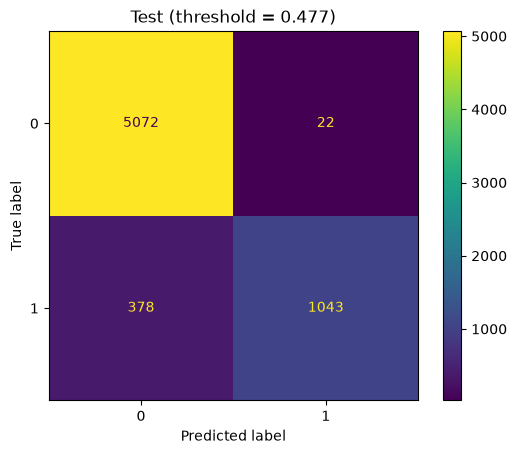


Training F1:                0.8727
Training balanced accuracy: 0.8890
Training ROC-AUC:           0.9855
Training average precision: 0.9661

Training classification report:
              precision    recall  f1-score   support

           0      0.942     0.998     0.969     20373
           1      0.990     0.780     0.873      5686

    accuracy                          0.950     26059
   macro avg      0.966     0.889     0.921     26059
weighted avg      0.953     0.950     0.948     26059



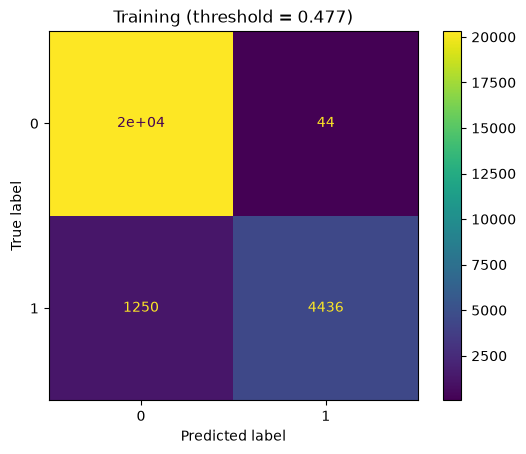

In [189]:
study = optuna_study(ntrials=120)
pipeline, threshold = retrain_and_evaluate(
    study, folds, preprocessor, X_train, y_train, X_test, y_test
)

In [190]:
# params importance
optuna.importance.get_param_importances(study)

{'gamma': 0.2952646425518928,
 'reg_alpha': 0.2753671069343887,
 'min_child_weight': 0.1501756971768015,
 'subsample': 0.12812336132406282,
 'colsample_bytree': 0.05480017751222417,
 'eta': 0.043983584772494956,
 'max_depth': 0.02784143231192932,
 'reg_lambda': 0.024443997416205836}

In [191]:
df = study.trials_dataframe()
top = df.sort_values("value", ascending=False).head(15)
print(top[["value", "params_max_depth", "params_min_child_weight", "params_gamma", "params_subsample", "params_colsample_bytree", "params_reg_lambda"]])
df.groupby("params_max_depth")["value"].agg(["max", "mean", "count"])

        value  params_max_depth  params_min_child_weight  params_gamma  \
102  0.848995                 7                 1.617097      1.680768   
86   0.848886                 7                 1.592492      1.321835   
105  0.848859                 7                 1.086672      1.601466   
103  0.848775                 7                 1.086958      0.981152   
114  0.848771                 7                 2.185137      1.466421   
88   0.848766                 7                 1.448963      1.400703   
108  0.848716                 7                 1.139258      1.669361   
100  0.848687                 7                 1.670010      1.692826   
59   0.848612                 7                 1.445939      1.513066   
71   0.848577                 7                 1.480584      1.318742   
61   0.848570                 7                 1.718781      1.169649   
63   0.848551                 7                 1.605368      1.793548   
97   0.848532                 7       

,max,mean,count
params_max_depth,,,
4,0.825368,0.824995,2
5,0.846465,0.843470,5
6,0.847814,0.844873,16
7,0.848995,0.847249,97


## <font color="orange">SHAP feature importance <font>

100%|===================| 1195/1200 [00:53<00:00]        

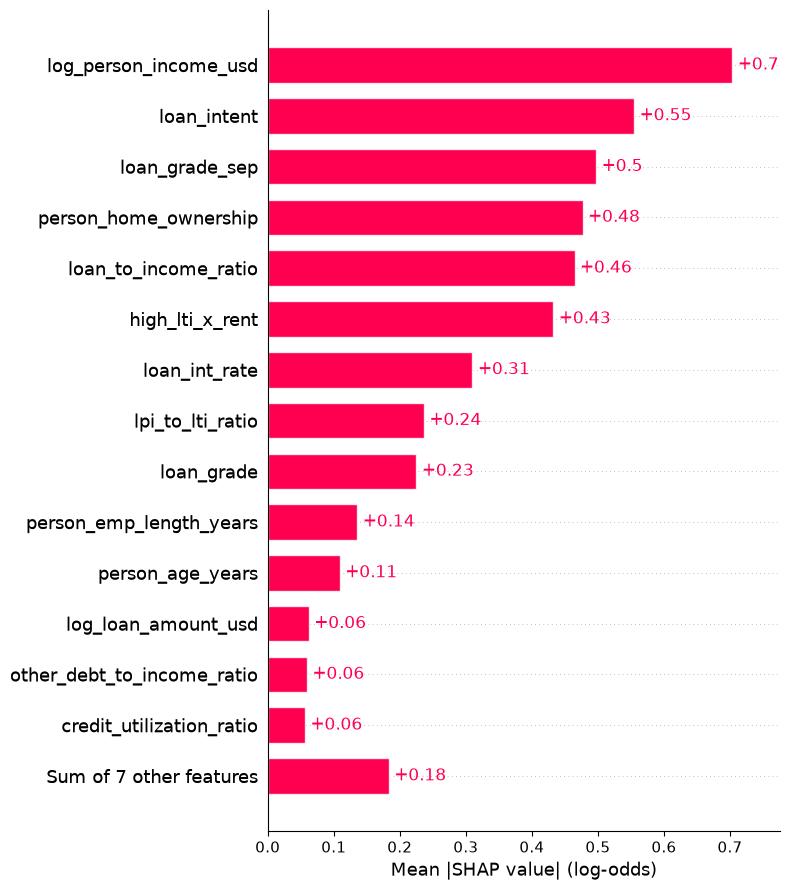

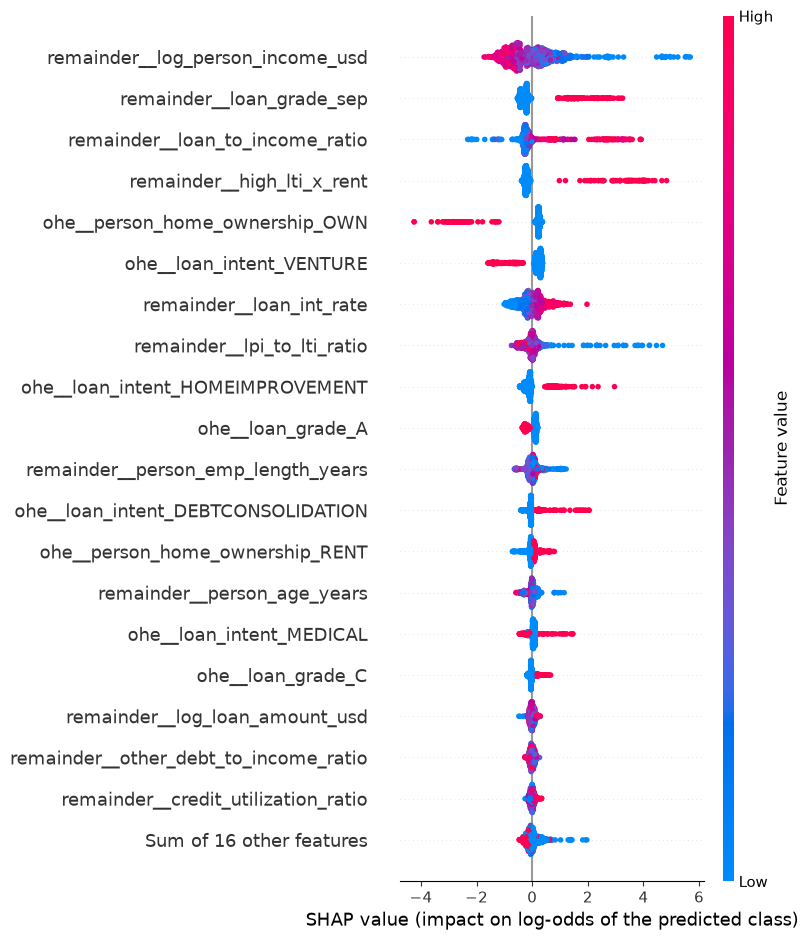

In [192]:
# Explain a manageable sample of the held-out data
background_raw = X_train # reference population
explain_raw = X_test # population to explain

# Background: 200-400 rows is enough for a tree explainer's reference distribution
rng = np.random.RandomState(42)
bg_idx = rng.choice(len(background_raw), size=min(400, len(background_raw)), replace=False)
explain_idx = rng.choice(len(explain_raw), size=min(1200, len(explain_raw)), replace=False)

# Extract necessary info from the best pipeline
preprocessor = pipeline.named_steps["preprocessor"]
best_clf = pipeline.named_steps["classifier"]
feature_names = preprocessor.get_feature_names_out()

# preprocessing transform to get what enter the classifier
background = preprocessor.transform(background_raw.iloc[bg_idx])
explain_data = preprocessor.transform(explain_raw.iloc[explain_idx])

# Convert sparse matrices to dense if necessary
if hasattr(background, "toarray"):
    background = background.toarray()
if hasattr(explain_data, "toarray"):
    explain_data = explain_data.toarray()
# wrap to dataframes
background = pd.DataFrame(background, columns=feature_names, index=background_raw.index[bg_idx])
explain_data = pd.DataFrame(explain_data, columns=feature_names, index=explain_raw.index[explain_idx])

# calculate SHAP values. LinearExplainer for Logit
masker = shap.maskers.Independent(background, max_samples=len(background))
explainer = shap.TreeExplainer(best_clf, masker)
shap_values = explainer(explain_data)

# Map each encoded column back to its original feature
def to_original(fname, raw_cols): # raw_cols: original cols
    stripped = fname.split("__", 1)[-1]  # drop transformer prefix
    # a col belongs to an original feature c if name=c (like numetics) or starts with c_ (OHE) 
    matches = [c for c in raw_cols if stripped == c or stripped.startswith(c + "_")]
    return max(matches, key=len) if matches else stripped  # longest match avoids prefix clashes

groups = np.array([to_original(f, X_train.columns) for f in feature_names])

# Sum SHAP values within each original feature per sample, then take the mean absolute value.
# SHAP is additive, so summing signed values per sample is the correct way to aggregate.
agg_df = (
    pd.DataFrame(shap_values.values, columns=feature_names)
    .T.groupby(groups).sum().T
)
agg_exp = shap.Explanation(
    values=agg_df.values,
    base_values=shap_values.base_values,
    feature_names=list(agg_df.columns),
)

# Importance per ORIGINAL feature (one-hot levels combined)
shap.plots.bar(agg_exp, max_display=15, show=False)
plt.xlabel("Mean |SHAP value| (log-odds)")
plt.tight_layout()
plt.show()

# Direction of impact per ENCODED feature (colors need the encoded values)
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.xlabel("SHAP value (impact on log-odds of the predicted class)")
plt.tight_layout()
plt.show()
